 0. Importation des Bibliothèques

In [1]:
# Manipulation des données
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, GridSearchCV)

# Modèles
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                               AdaBoostClassifier, GradientBoostingClassifier)

# Métriques
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

# Divers
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(" Toutes les bibliothèques importées avec succès !")

 Toutes les bibliothèques importées avec succès !


1. Acquisition des Données

In [8]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print(f"\n Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print("\n Aperçu des premières lignes :")
df.head(10)
# Informations générales
print("=" * 60)
print(" INFORMATIONS GÉNÉRALES DU DATASET")
print("=" * 60)
df.info()
# Statistiques descriptives
print(" STATISTIQUES DESCRIPTIVES")
df.describe(include='all').round(2)



 Dimensions : 5110 lignes x 12 colonnes

 Aperçu des premières lignes :
 INFORMATIONS GÉNÉRALES DU DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
 STATISTIQUES DESCRIPTIVES


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.00,5110,5110.00,5110.0,5110.00,5110,5110,5110,5110.00,4909.00,5110,5110.00
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.83,NaN,43.23,0.1,0.05,NaN,NaN,NaN,106.15,28.89,NaN,0.05
std,21161.72,NaN,22.61,0.3,0.23,NaN,NaN,NaN,45.28,7.85,NaN,0.22
min,67.00,NaN,0.08,0.0,0.00,NaN,NaN,NaN,55.12,10.30,NaN,0.00
25%,17741.25,NaN,25.00,0.0,0.00,NaN,NaN,NaN,77.24,23.50,NaN,0.00
50%,36932.00,NaN,45.00,0.0,0.00,NaN,NaN,NaN,91.88,28.10,NaN,0.00
75%,54682.00,NaN,61.00,0.0,0.00,NaN,NaN,NaN,114.09,33.10,NaN,0.00


2. Prétraitement des Données

 2.1 Identification des Valeurs Manquantes


 Valeurs manquantes par colonne :

     Manquantes  Pourcentage (%)
bmi         201             3.93


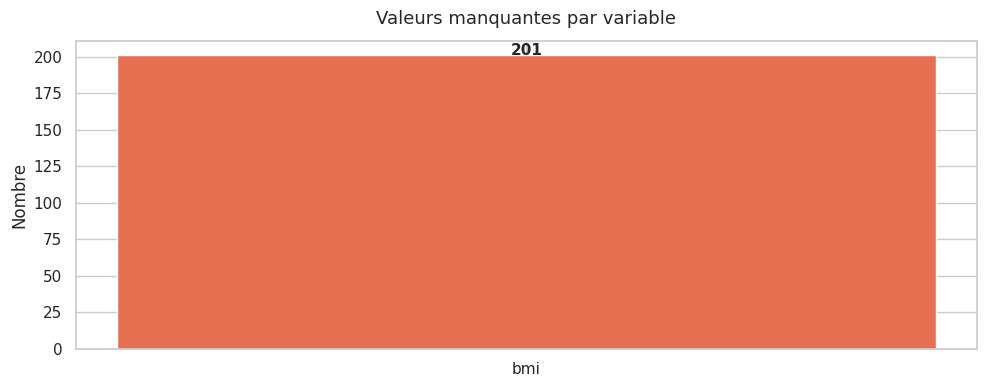

In [10]:
# Valeurs manquantes
print(" Valeurs manquantes par colonne :\n")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Manquantes': missing, 'Pourcentage (%)': missing_pct})
print(missing_df[missing_df['Manquantes'] > 0])

# Visualisation
fig, ax = plt.subplots(figsize=(10, 4))
cols_with_missing = missing[missing > 0]
if len(cols_with_missing) > 0:
    bars = ax.bar(cols_with_missing.index, cols_with_missing.values,
                  color='#E76F51', edgecolor='white')
    for bar, val in zip(bars, cols_with_missing.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(val), ha='center', fontweight='bold')
    ax.set_title("Valeurs manquantes par variable", fontsize=13, pad=12)
    ax.set_ylabel("Nombre")
    plt.tight_layout()
    plt.savefig('missing_values.png', bbox_inches='tight')
    plt.show()
else:
    print("\n Aucune valeur manquante détectée !")

2.2 Nettoyage des Données

In [11]:
# Supprimer la colonne 'id' (non pertinente)
df = df.drop(columns=['id'], errors='ignore')
print(" Colonne 'id' supprimée")

# Supprimer la ligne avec gender = 'Other' (1 seule occurrence)
df = df[df['gender'] != 'Other']
print(f" Lignes avec gender='Other' supprimées — Dimensions : {df.shape}")

# Imputation BMI (valeurs manquantes) par la médiane
if df['bmi'].isnull().sum() > 0:
    df['bmi'] = df['bmi'].fillna(df['bmi'].median())
    print(f" BMI — valeurs manquantes imputées par la médiane ({df['bmi'].median():.1f})")

# Vérification finale
print(f"\n Valeurs manquantes restantes : {df.isnull().sum().sum()}")
print(f" Dimensions finales : {df.shape}")

 Colonne 'id' supprimée
 Lignes avec gender='Other' supprimées — Dimensions : (5109, 11)
 BMI — valeurs manquantes imputées par la médiane (28.1)

 Valeurs manquantes restantes : 0
 Dimensions finales : (5109, 11)


2.3 Encodage des Variables Catégorielles

In [12]:
# Afficher les variables catégorielles et leurs valeurs uniques
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(" Variables catégorielles détectées :\n")
for col in cat_cols:
    print(f"  {col:<20} : {df[col].unique()}")
# Encodage — Label Encoding pour les variables binaires
#            One-Hot Encoding pour les variables multi-classes

df_encoded = df.copy()

# Label Encoding (binaires)
le = LabelEncoder()
binary_cols = ['gender', 'ever_married', 'Residence_type']
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])
    print(f"  Label Encoding : {col}")

# One-Hot Encoding (multi-classes)
ohe_cols = ['work_type', 'smoking_status']
df_encoded = pd.get_dummies(df_encoded, columns=ohe_cols, drop_first=True)
print(f"  One-Hot Encoding : {ohe_cols}")

print(f"\n Encodage terminé")
print(f" Dimensions après encodage : {df_encoded.shape}")
print(f"\n Colonnes finales :\n{df_encoded.columns.tolist()}")



 Variables catégorielles détectées :

  gender               : ['Male' 'Female']
  ever_married         : ['Yes' 'No']
  work_type            : ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
  Residence_type       : ['Urban' 'Rural']
  smoking_status       : ['formerly smoked' 'never smoked' 'smokes' 'Unknown']
  Label Encoding : gender
  Label Encoding : ever_married
  Label Encoding : Residence_type
  One-Hot Encoding : ['work_type', 'smoking_status']

 Encodage terminé
 Dimensions après encodage : (5109, 16)

 Colonnes finales :
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'stroke', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


2.4 Normalisation et Split Train/Test

In [14]:
# Séparation features / target
X = df_encoded.drop('stroke', axis=1)
y = df_encoded['stroke']

print(" Features X :", X.shape)
print(" Target  y :", y.shape)
print("\n Distribution de la variable cible :")
vc = y.value_counts()
print(f"  Pas d'AVC (0) : {vc[0]} ({vc[0]/len(y)*100:.1f}%)")
print(f"  AVC       (1) : {vc[1]} ({vc[1]/len(y)*100:.1f}%)")
print("\n  Dataset déséquilibré — à prendre en compte dans l'évaluation !")
# Normalisation (StandardScaler)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Split train/test (80/20, stratifié)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(" Normalisation (StandardScaler) effectuée")
print(" Split Train/Test (stratifié) effectué")
print(f"\n  Train : {X_train.shape[0]} instances")
print(f"  Test  : {X_test.shape[0]} instances")

 Features X : (5109, 15)
 Target  y : (5109,)

 Distribution de la variable cible :
  Pas d'AVC (0) : 4860 (95.1%)
  AVC       (1) : 249 (4.9%)

  Dataset déséquilibré — à prendre en compte dans l'évaluation !
 Normalisation (StandardScaler) effectuée
 Split Train/Test (stratifié) effectué

  Train : 4087 instances
  Test  : 1022 instances


3. Exploration et Visualisation (EDA)

In [ ]:
# Distribution de la variable cible
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = y.value_counts()
axes[0].pie(counts, labels=['Pas d\'AVC (95.1%)', 'AVC (4.9%)'],
            colors=['#2A9D8F', '#E76F51'], autopct='%1.1f%%',
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title("Distribution de la variable cible", fontsize=13, pad=12)

axes[1].bar(['Pas d\'AVC (0)', 'AVC (1)'], counts.values,
            color=['#2A9D8F', '#E76F51'], edgecolor='white')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 20, str(v), ha='center', fontweight='bold')
axes[1].set_title("Nombre d'instances par classe", fontsize=13, pad=12)
axes[1].set_ylabel("Nombre d'instances")

plt.tight_layout()
plt.savefig('target_distribution.png', bbox_inches='tight')
plt.show()


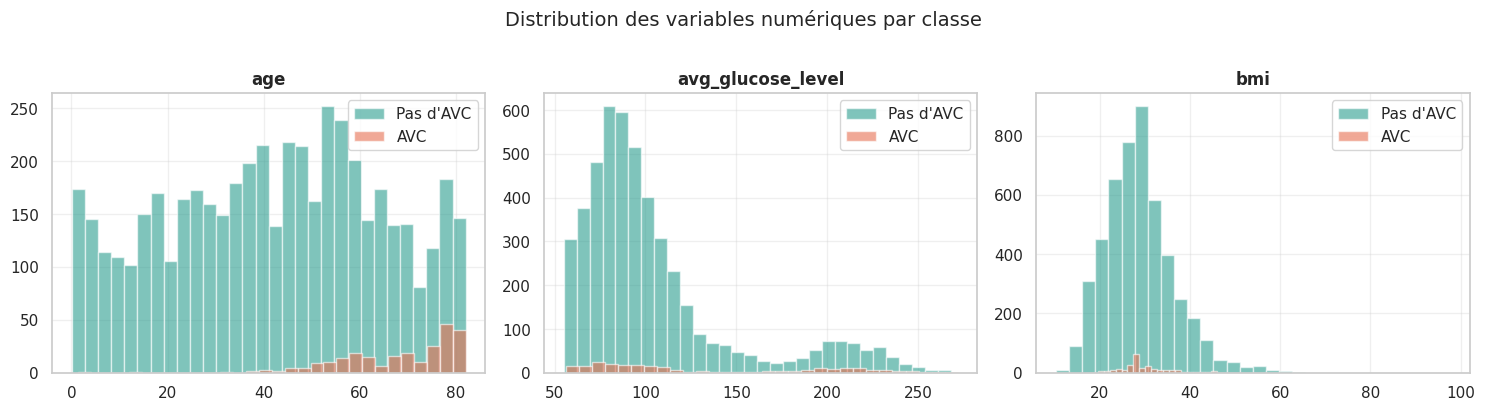

In [ ]:
# Distribution des variables numériques par classe
num_cols = ['age', 'avg_glucose_level', 'bmi']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(num_cols):
    df[df['stroke'] == 0][col].hist(ax=axes[i], alpha=0.6, color='#2A9D8F',
                                     bins=30, label='Pas d\'AVC', edgecolor='white')
    df[df['stroke'] == 1][col].hist(ax=axes[i], alpha=0.6, color='#E76F51',
                                     bins=30, label='AVC', edgecolor='white')
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Distribution des variables numériques par classe", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('num_distribution.png', bbox_inches='tight')
plt.show()

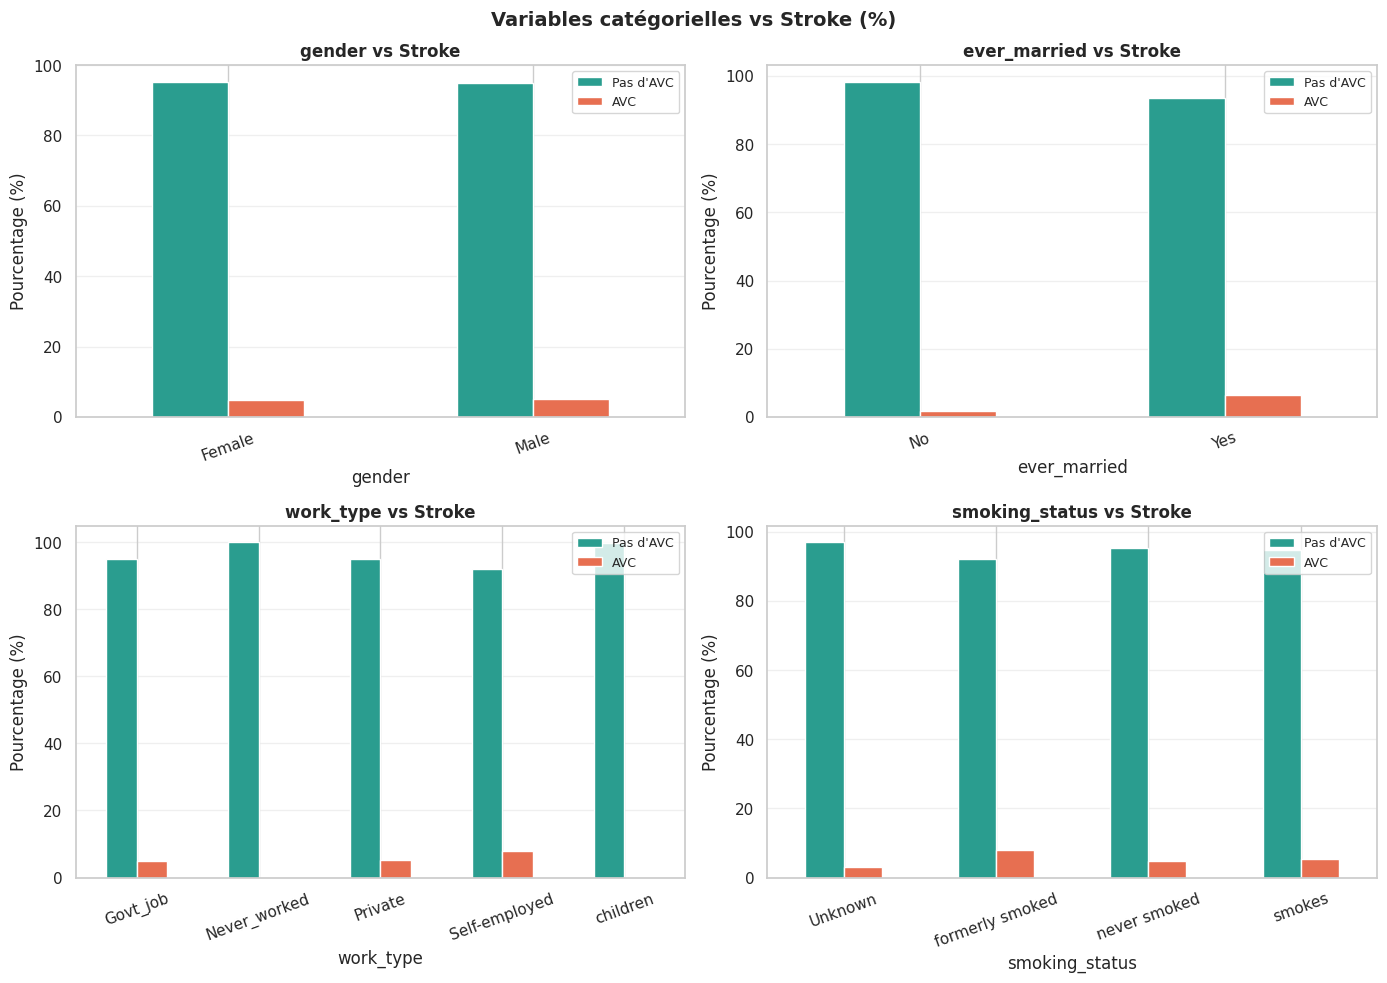

In [ ]:
# Variables catégorielles vs Stroke
cat_plot_cols = ['gender', 'ever_married', 'work_type', 'smoking_status']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_plot_cols):
    ct = pd.crosstab(df[col], df['stroke'], normalize='index') * 100
    ct.columns = ['Pas d\'AVC', 'AVC']
    ct.plot(kind='bar', ax=axes[i], color=['#2A9D8F', '#E76F51'],
            edgecolor='white', rot=20)
    axes[i].set_title(f"{col} vs Stroke", fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Pourcentage (%)")
    axes[i].legend(fontsize=9)
    axes[i].grid(True, alpha=0.3, axis='y')

plt.suptitle("Variables catégorielles vs Stroke (%)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('cat_vs_stroke.png', bbox_inches='tight')
plt.show()


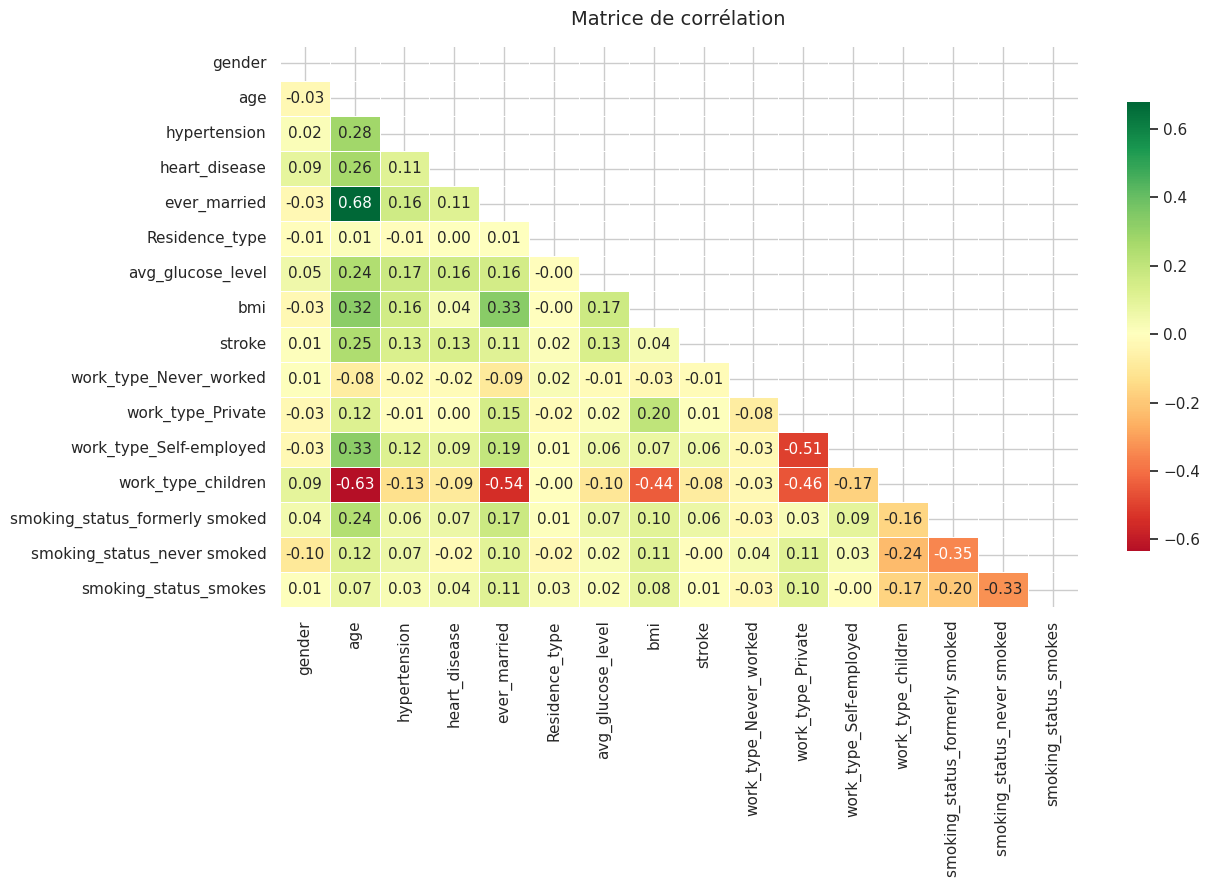


 Corrélations avec 'stroke' (top variables) :
age                  0.245
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
ever_married         0.108
Name: stroke, dtype: float64


In [18]:
# Matrice de corrélation
fig, ax = plt.subplots(figsize=(13, 9))
corr = df_encoded.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            mask=mask, ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title("Matrice de corrélation", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('correlation_matrix.png', bbox_inches='tight')
plt.show()

print("\n Corrélations avec 'stroke' (top variables) :")
print(corr['stroke'].sort_values(ascending=False)[1:6].round(3))

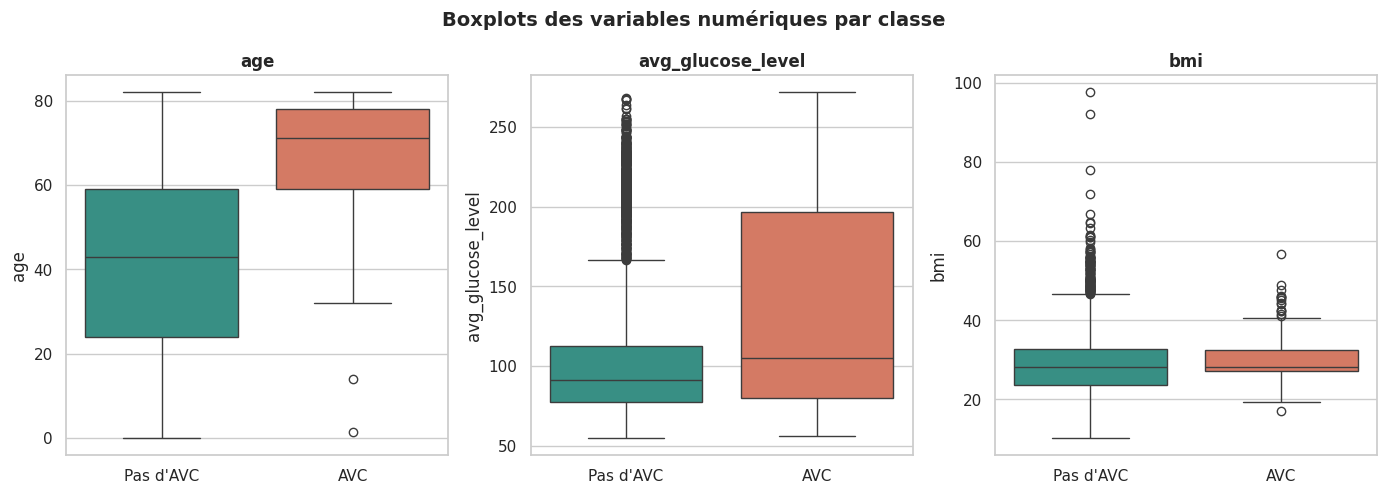

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
num_vars = ['age', 'avg_glucose_level', 'bmi']

for i, col in enumerate(num_vars):
    # Convertir stroke en string d'abord
    temp_df = df.copy()
    temp_df['stroke_label'] = temp_df['stroke'].map(
        {0: "Pas d'AVC", 1: 'AVC'}
    )
    sns.boxplot(
        data=temp_df,
        x='stroke_label',
        y=col,
        ax=axes[i],
        palette={"Pas d'AVC": '#2A9D8F', 'AVC': '#E76F51'},
        order=["Pas d'AVC", 'AVC']
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle("Boxplots des variables numériques par classe",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('boxplots.png', bbox_inches='tight')
plt.show()

 4. Sélection et Entraînement des Modèles

On va entraîner **5 algorithmes** de classification avec validation croisée (10-fold stratifiée) :
- Régression Logistique
- K-Plus Proches Voisins (KNN)
- Support Vector Machine (SVM)
- Arbre de Décision
- Forêt Aléatoire


In [20]:
# Définition des modèles
models = {
    'Régression Logistique' : LogisticRegression(random_state=42, max_iter=1000),
    'KNN (k=5)'             : KNeighborsClassifier(n_neighbors=5),
    'SVM (RBF)'             : SVC(kernel='rbf', probability=True, random_state=42),
    'Arbre de Décision'     : DecisionTreeClassifier(random_state=42),
    'Forêt Aléatoire'       : RandomForestClassifier(n_estimators=100, random_state=42),
}

# Validation croisée stratifiée (10-fold)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_results = {}

print(" Validation croisée (10-fold stratifiée) en cours...\n")
print(f"{'Modèle':<28} {'Accuracy':>10} {'Std':>8}")
print("-" * 50)

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name:<28} {scores.mean():.4f} ± {scores.std():.4f}")

print("\n Validation croisée terminée !")

 Validation croisée (10-fold stratifiée) en cours...

Modèle                         Accuracy      Std
--------------------------------------------------
Régression Logistique        0.9511 ± 0.0011
KNN (k=5)                    0.9474 ± 0.0049
SVM (RBF)                    0.9513 ± 0.0007
Arbre de Décision            0.9060 ± 0.0114
Forêt Aléatoire              0.9494 ± 0.0022

 Validation croisée terminée !


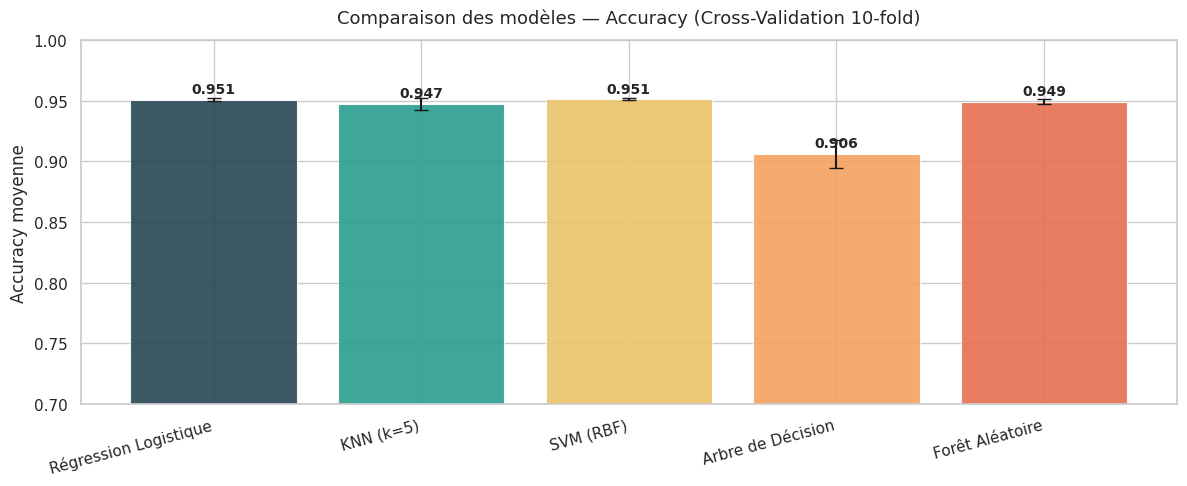

In [21]:
# Visualisation des résultats CV
fig, ax = plt.subplots(figsize=(12, 5))
names = list(cv_results.keys())
means = [cv_results[n].mean() for n in names]
stds  = [cv_results[n].std()  for n in names]
colors = ['#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E76F51']

bars = ax.bar(names, means, yerr=stds, capsize=5, color=colors,
              edgecolor='white', linewidth=0.8, alpha=0.9)
for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{mean:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0.7, 1.0)
ax.set_title("Comparaison des modèles — Accuracy (Cross-Validation 10-fold)", fontsize=13, pad=12)
ax.set_ylabel("Accuracy moyenne")
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('cv_comparison.png', bbox_inches='tight')
plt.show()

 5. Méthodes Ensemblistes (Bagging & Boosting)

In [22]:
# Méthodes ensemblistes
ensemble_models = {
    'Bagging (DT)'       : BaggingClassifier(estimator=DecisionTreeClassifier(),
                                              n_estimators=100, random_state=42),
    'AdaBoost'           : AdaBoostClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting'  : GradientBoostingClassifier(n_estimators=100, random_state=42),
}

print(" Méthodes ensemblistes — Validation croisée (10-fold)...\n")
print(f"{'Modèle':<25} {'Accuracy':>10} {'Std':>8}")
print("-" * 45)

for name, model in ensemble_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name:<25} {scores.mean():.4f} ± {scores.std():.4f}")

print("\n Méthodes ensemblistes évaluées !")

 Méthodes ensemblistes — Validation croisée (10-fold)...

Modèle                      Accuracy      Std
---------------------------------------------
Bagging (DT)              0.9486 ± 0.0022
AdaBoost                  0.9511 ± 0.0011
Gradient Boosting         0.9491 ± 0.0028

 Méthodes ensemblistes évaluées !


6. Évaluation Complète sur le Jeu de Test

In [23]:
# Entraînement et évaluation sur test set — tous les modèles
all_models = {**models, **ensemble_models}
results = []

for name, model in all_models.items():
    model.fit(X_train, y_train)
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results.append({
        'Modèle'    : name,
        'Accuracy'  : accuracy_score(y_test, y_pred),
        'Précision' : precision_score(y_test, y_pred, zero_division=0),
        'Rappel'    : recall_score(y_test, y_pred, zero_division=0),
        'F1-Score'  : f1_score(y_test, y_pred, zero_division=0),
        'AUC-ROC'   : roc_auc_score(y_test, y_proba),
    })

results_df = (pd.DataFrame(results)
                .set_index('Modèle')
                .sort_values('AUC-ROC', ascending=False))

print(" TABLEAU COMPARATIF — Jeu de test\n")
print(results_df.round(4).to_string())

 TABLEAU COMPARATIF — Jeu de test

                       Accuracy  Précision  Rappel  F1-Score  AUC-ROC
Modèle                                                               
Régression Logistique    0.9521     1.0000    0.02    0.0392   0.8394
AdaBoost                 0.9521     1.0000    0.02    0.0392   0.8263
Gradient Boosting        0.9481     0.2000    0.02    0.0364   0.8084
Forêt Aléatoire          0.9501     0.0000    0.00    0.0000   0.7868
Bagging (DT)             0.9462     0.0000    0.00    0.0000   0.7600
SVM (RBF)                0.9511     0.0000    0.00    0.0000   0.6409
KNN (k=5)                0.9491     0.2500    0.02    0.0370   0.6090
Arbre de Décision        0.9110     0.1639    0.20    0.1802   0.5738


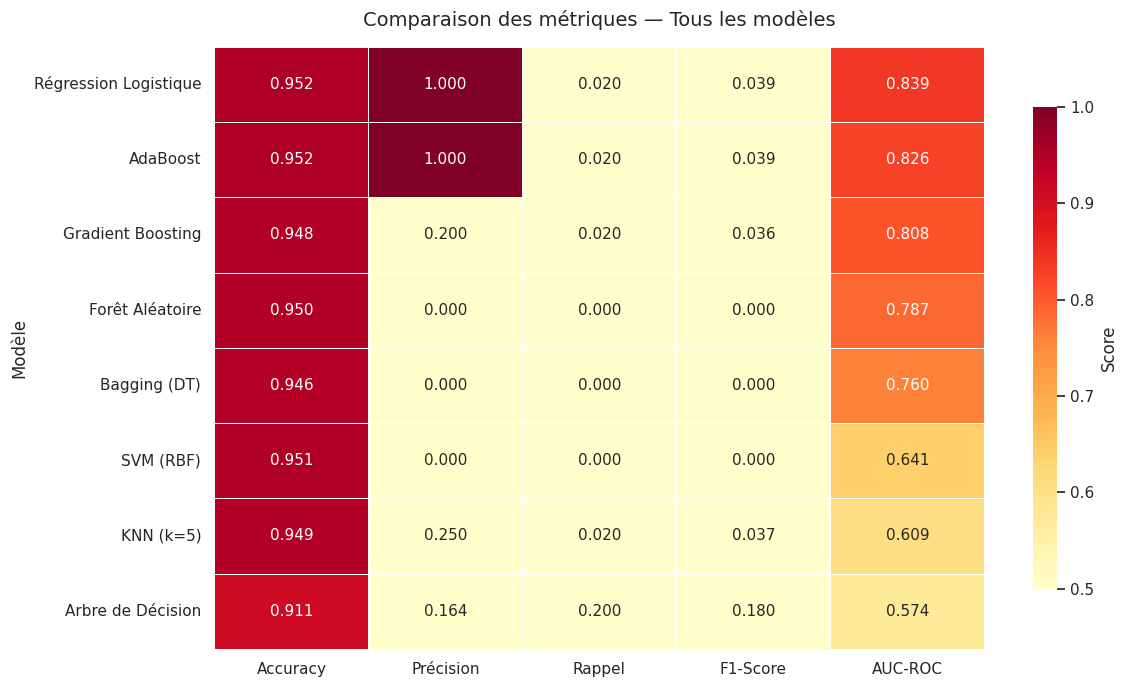

In [ ]:
# Heatmap des métriques
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(results_df, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, vmin=0.5, vmax=1.0,
            cbar_kws={'shrink': 0.8, 'label': 'Score'})
ax.set_title("Comparaison des métriques — Tous les modèles", fontsize=14, pad=15)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('metrics_heatmap.png', bbox_inches='tight')
plt.show()


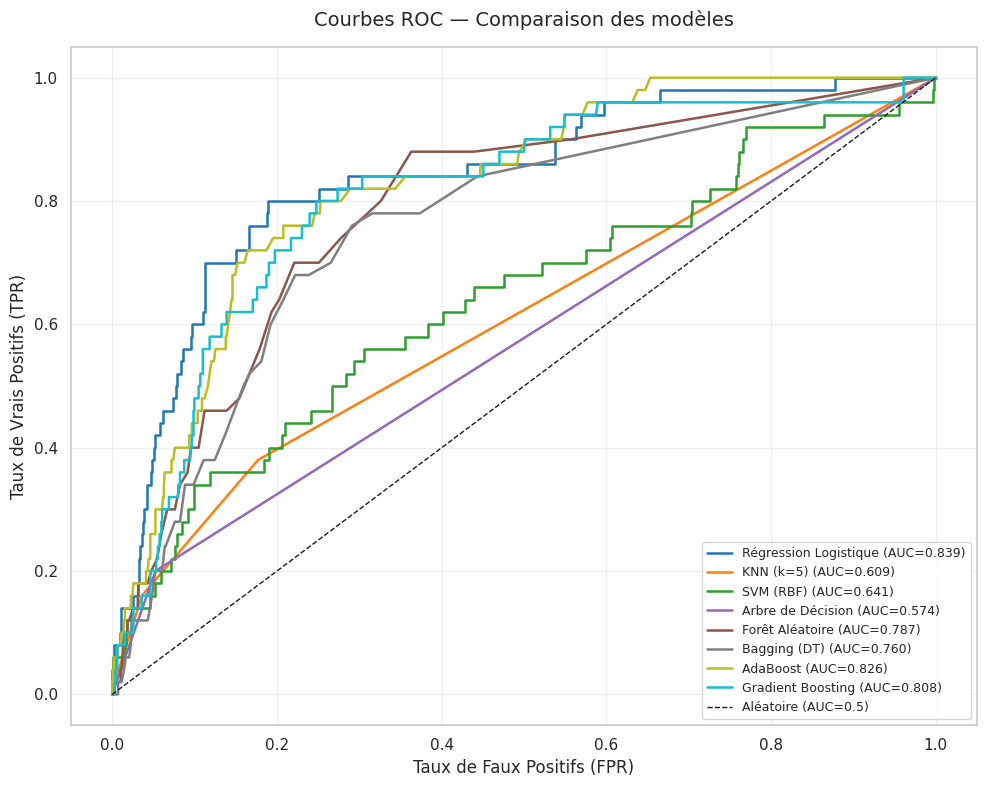

In [ ]:
# Courbes ROC — tous les modèles
fig, ax = plt.subplots(figsize=(10, 8))
colors_roc = plt.cm.tab10(np.linspace(0, 1, len(all_models)))

for (name, model), color in zip(all_models.items(), colors_roc):
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=color, linewidth=1.8)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Aléatoire (AUC=0.5)')
ax.set_xlabel("Taux de Faux Positifs (FPR)", fontsize=12)
ax.set_ylabel("Taux de Vrais Positifs (TPR)", fontsize=12)
ax.set_title("Courbes ROC — Comparaison des modèles", fontsize=14, pad=15)
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', bbox_inches='tight')
plt.show()


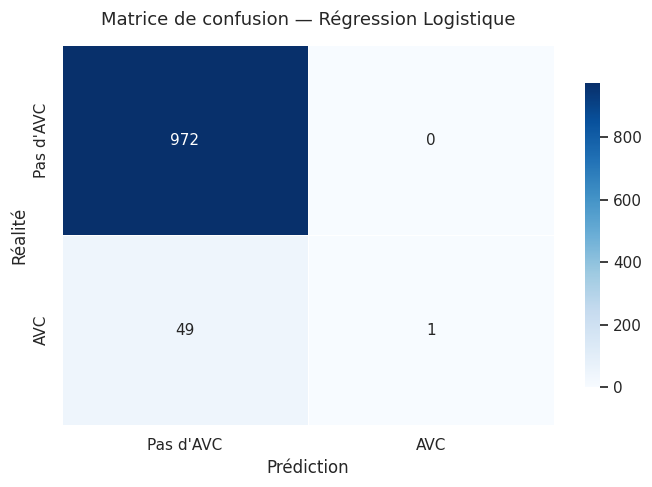


 Rapport de classification — Régression Logistique :

              precision    recall  f1-score   support

   Pas d'AVC       0.95      1.00      0.98       972
         AVC       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



In [24]:
# Matrice de confusion — Meilleur modèle
best_name = results_df['AUC-ROC'].idxmax()
best_model = all_models[best_name]
y_pred_best = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=["Pas d'AVC", 'AVC'],
            yticklabels=["Pas d'AVC", 'AVC'],
            linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_xlabel("Prédiction", fontsize=12)
ax.set_ylabel("Réalité", fontsize=12)
ax.set_title(f"Matrice de confusion — {best_name}", fontsize=13, pad=15)
plt.tight_layout()
plt.savefig('confusion_matrix.png', bbox_inches='tight')
plt.show()

print(f"\n Rapport de classification — {best_name} :\n")
print(classification_report(y_test, y_pred_best,
      target_names=["Pas d'AVC", 'AVC']))

 7. Optimisation des Hyperparamètres (GridSearchCV)

In [25]:
# GridSearchCV — Gradient Boosting
param_grid_gb = {
    'n_estimators'  : [100, 200],
    'learning_rate' : [0.05, 0.1, 0.2],
    'max_depth'     : [3, 4, 5],
    'subsample'     : [0.8, 1.0],
}

print(" GridSearchCV — Gradient Boosting en cours (~1-2 min)...\n")
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb, cv=5, scoring='roc_auc', n_jobs=-1, verbose=0
)
gb_grid.fit(X_train, y_train)

print("Meilleurs hyperparamètres — Gradient Boosting :")
for k, v in gb_grid.best_params_.items():
    print(f"   {k:<20} : {v}")
print(f"\n   AUC-ROC (CV) avant optimisation : {results_df.loc[best_name, 'AUC-ROC'] if best_name in results_df.index else 'N/A'}")
print(f"   AUC-ROC (CV) après optimisation : {gb_grid.best_score_:.4f}")

 GridSearchCV — Gradient Boosting en cours (~1-2 min)...

Meilleurs hyperparamètres — Gradient Boosting :
   learning_rate        : 0.05
   max_depth            : 3
   n_estimators         : 100
   subsample            : 0.8

   AUC-ROC (CV) avant optimisation : 0.8393827160493827
   AUC-ROC (CV) après optimisation : 0.8536


In [26]:
# Évaluation du modèle optimisé
best_gb = gb_grid.best_estimator_
y_pred_opt  = best_gb.predict(X_test)
y_proba_opt = best_gb.predict_proba(X_test)[:, 1]

print(" Gradient Boosting OPTIMISÉ — Résultats finaux :\n")
print(f"  Accuracy  : {accuracy_score(y_test, y_pred_opt):.4f}")
print(f"  Précision : {precision_score(y_test, y_pred_opt, zero_division=0):.4f}")
print(f"  Rappel    : {recall_score(y_test, y_pred_opt, zero_division=0):.4f}")
print(f"  F1-Score  : {f1_score(y_test, y_pred_opt, zero_division=0):.4f}")
print(f"  AUC-ROC   : {roc_auc_score(y_test, y_proba_opt):.4f}")
print(f"\n{classification_report(y_test, y_pred_opt, target_names=["Pas d'AVC", 'AVC'])}")

 Gradient Boosting OPTIMISÉ — Résultats finaux :

  Accuracy  : 0.9511
  Précision : 0.5000
  Rappel    : 0.0200
  F1-Score  : 0.0385
  AUC-ROC   : 0.8257

              precision    recall  f1-score   support

   Pas d'AVC       0.95      1.00      0.97       972
         AVC       0.50      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.73      0.51      0.51      1022
weighted avg       0.93      0.95      0.93      1022



In [27]:
# GridSearchCV — Random Forest
param_grid_rf = {
    'n_estimators'     : [100, 200],
    'max_depth'        : [None, 5, 10],
    'min_samples_split': [2, 5],
    'max_features'     : ['sqrt', 'log2'],
}

print(" GridSearchCV — Random Forest en cours...\n")
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf, cv=5, scoring='roc_auc', n_jobs=-1, verbose=0
)
rf_grid.fit(X_train, y_train)

print(" Meilleurs hyperparamètres — Random Forest :")
for k, v in rf_grid.best_params_.items():
    print(f"   {k:<25} : {v}")
print(f"\n   AUC-ROC (CV) optimisé : {rf_grid.best_score_:.4f}")

 GridSearchCV — Random Forest en cours...

 Meilleurs hyperparamètres — Random Forest :
   max_depth                 : 5
   max_features              : sqrt
   min_samples_split         : 2
   n_estimators              : 200

   AUC-ROC (CV) optimisé : 0.8410


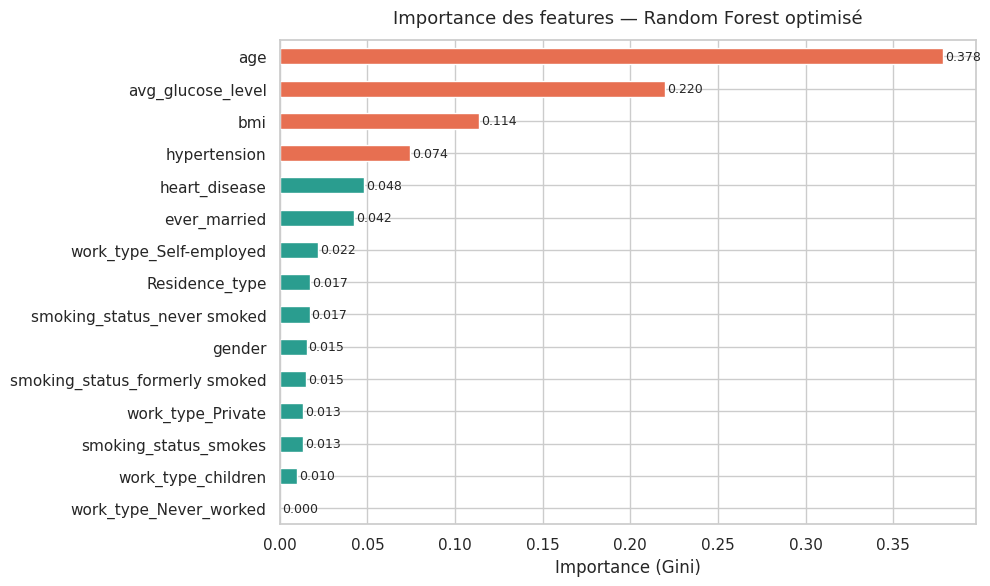

In [28]:
# Importance des features — Random Forest optimisé
best_rf = rf_grid.best_estimator_
importances = pd.Series(best_rf.feature_importances_,
                        index=X.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors_imp = ['#E76F51' if v >= importances.quantile(0.75) else '#2A9D8F'
              for v in importances.values]
importances.plot(kind='barh', ax=ax, color=colors_imp, edgecolor='white')
ax.set_title("Importance des features — Random Forest optimisé", fontsize=13, pad=12)
ax.set_xlabel("Importance (Gini)")
for i, v in enumerate(importances.values):
    ax.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight')
plt.show()

 8. Conclusion et Synthèse des Résultats

In [30]:
# Tableau de synthèse final
y_pred_opt_rf  = best_rf.predict(X_test)
y_proba_opt_rf = best_rf.predict_proba(X_test)[:, 1]

final_rows = pd.DataFrame([
    {
        'Modèle'    : 'Gradient Boosting (optimisé) ',
        'Accuracy'  : accuracy_score(y_test, y_pred_opt),
        'Précision' : precision_score(y_test, y_pred_opt, zero_division=0),
        'Rappel'    : recall_score(y_test, y_pred_opt, zero_division=0),
        'F1-Score'  : f1_score(y_test, y_pred_opt, zero_division=0),
        'AUC-ROC'   : roc_auc_score(y_test, y_proba_opt),
    },
    {
        'Modèle'    : 'Random Forest (optimisé) ',
        'Accuracy'  : accuracy_score(y_test, y_pred_opt_rf),
        'Précision' : precision_score(y_test, y_pred_opt_rf, zero_division=0),
        'Rappel'    : recall_score(y_test, y_pred_opt_rf, zero_division=0),
        'F1-Score'  : f1_score(y_test, y_pred_opt_rf, zero_division=0),
        'AUC-ROC'   : roc_auc_score(y_test, y_proba_opt_rf),
    },
]).set_index('Modèle')

final_df = pd.concat([results_df, final_rows]).sort_values('AUC-ROC', ascending=False)

print("=" * 75)
print(" SYNTHÈSE FINALE — TOUS LES MODÈLES")
print("=" * 75)
print(final_df.round(4).to_string())


 SYNTHÈSE FINALE — TOUS LES MODÈLES
                               Accuracy  Précision  Rappel  F1-Score  AUC-ROC
Modèle                                                                       
Régression Logistique            0.9521     1.0000    0.02    0.0392   0.8394
Random Forest (optimisé)         0.9511     0.0000    0.00    0.0000   0.8367
AdaBoost                         0.9521     1.0000    0.02    0.0392   0.8263
Gradient Boosting (optimisé)     0.9511     0.5000    0.02    0.0385   0.8257
Gradient Boosting                0.9481     0.2000    0.02    0.0364   0.8084
Forêt Aléatoire                  0.9501     0.0000    0.00    0.0000   0.7868
Bagging (DT)                     0.9462     0.0000    0.00    0.0000   0.7600
SVM (RBF)                        0.9511     0.0000    0.00    0.0000   0.6409
KNN (k=5)                        0.9491     0.2500    0.02    0.0370   0.6090
Arbre de Décision                0.9110     0.1639    0.20    0.1802   0.5738
